# Product and Department Performance

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('../data/processed/dataset.csv', parse_dates=['order_date', 'shipping_date'])

In [2]:
sns.set_theme()

from scripts import visualization_config

## Which product categories sell the most units

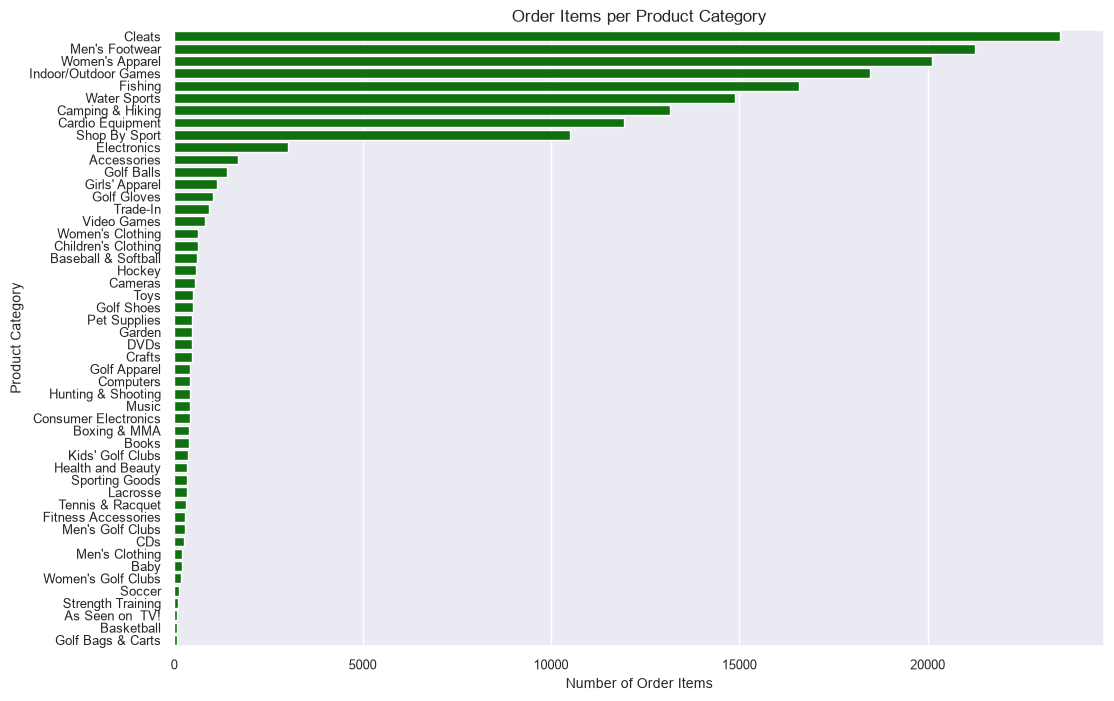

In [3]:
items_per_product_category = df.groupby('category_name').size().sort_values(ascending=False)

plt.figure(figsize=(12, 8))

sns.barplot(x=items_per_product_category.values, y=items_per_product_category.index, color='green')

plt.title('Order Items per Product Category')
plt.xlabel('Number of Order Items')
plt.ylabel('Product Category')

plt.savefig('../visualizations/order-items-per-product-category.png', bbox_inches='tight')
plt.show()

In [4]:
items_volume_per_category = (items_per_product_category / items_per_product_category.sum()).sort_values(ascending=False)

for category, volume in items_volume_per_category.head().items():
    print(f'{category}: {volume:.2%}')

Cleats: 13.61%
Men's Footwear: 12.31%
Women's Apparel: 11.64%
Indoor/Outdoor Games: 10.69%
Fishing: 9.61%


## Do certain product categories experience higher delivery delay rates?

In [5]:
overall_late_rate = df['late_delivery_risk'].mean()

category_delays = df.groupby('category_name')['late_delivery_risk'].agg(['mean', 'count'])
category_delays = category_delays[category_delays['count'] > 100]
category_delays['diff_from_overall'] = category_delays['mean'] - overall_late_rate

category_delays.sort_values('diff_from_overall', ascending=False)

,mean,count,diff_from_overall
category_name,,,
Lacrosse,0.626140,329,0.053240
Pet Supplies,0.614407,472,0.041507
Cameras,0.612100,562,0.039200
Accessories,0.597525,1697,0.024625
Music,0.594724,417,0.021825
Fitness Accessories,0.594595,296,0.021695
Boxing & MMA,0.592040,402,0.019140
Crafts,0.591703,458,0.018803
Sporting Goods,0.589286,336,0.016386


This table displays late delivery risk rates per product category, compared with the overall average late delivery risk.

It suggests that there aren't any product categories that experience higher delivery delay rates - the overall average late delivery risk being 57.29% with all items being at most +5 and -8 away from it.

Categories with fewer than 100 rows were excluded, as they produce noise.

To investigate further, I'll look at the average delivery delay in days for each category.

In [6]:
delayed_rows = df[df['late_delivery_risk'] == 1].copy()

delayed_rows['late_days'] = delayed_rows['days_for_shipping_real'] - delayed_rows['days_for_shipment_scheduled']

categories_average_delays = (
    delayed_rows
    .groupby('category_name')['late_days']
    .agg(['mean', 'count'])
)

filtered_categories = categories_average_delays[categories_average_delays['count'] > 100]

filtered_categories.sort_values('mean', ascending=False)

,mean,count
category_name,,
Trade-In,1.734317,542
Consumer Electronics,1.726891,238
Women's Clothing,1.700272,367
Children's Clothing,1.698276,348
Baseball & Softball,1.679083,349
Tennis & Racquet,1.666667,183
Video Games,1.665934,455
Computers,1.656250,224
Boxing & MMA,1.642857,238


The table unveils that baby products have the least amount of latency, 1.47 days on average, with trade-in items sitting at the top with 1.73 days on average.

These two categories are furthest apart and have a difference of 0.26 days difference on average.

This suggests that specific product categories don't experience higher delivery delay rates.

### Conclusion

Both tables suggest that no specific product categories experience higher delivery delay rates.

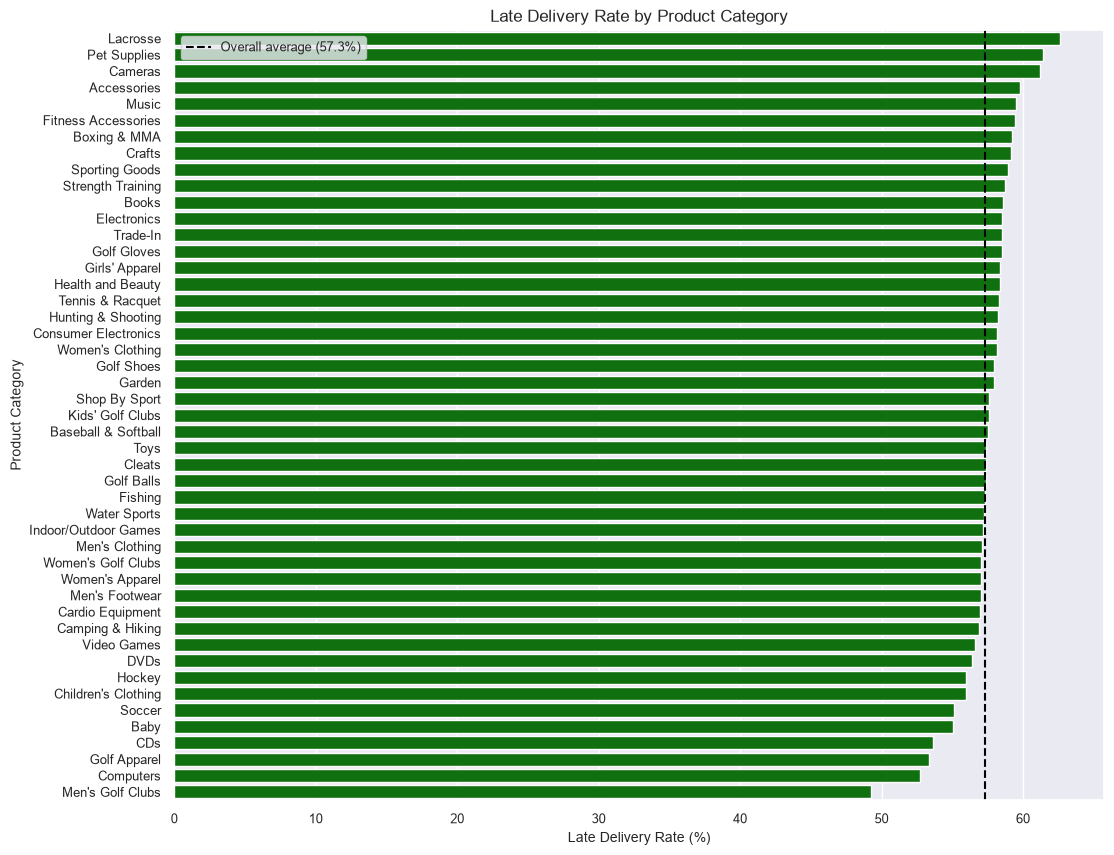

In [7]:
chart_data = category_delays.sort_values('mean', ascending=False)

plt.figure(figsize=(12, 10))

sns.barplot(x=chart_data['mean'] * 100, y=chart_data.index, color='green')
plt.axvline(overall_late_rate * 100, color='black', linestyle='--',
            label=f'Overall average ({overall_late_rate:.1%})')

plt.title('Late Delivery Rate by Product Category')
plt.xlabel('Late Delivery Rate (%)')
plt.ylabel('Product Category')
plt.legend()

plt.savefig('../visualizations/late-delivery-rate-by-product-category.png', bbox_inches='tight')
plt.show()

## Which departments generate the most revenue and profit?

In [8]:
profit_per_department = df.groupby('department_name')['order_item_profit'].sum().sort_values(ascending=False)

for department, profit in profit_per_department.items():
    print(f'{department}: ${profit:,.0f}')

Fan Shop: $1,759,601
Apparel: $845,530
Golf: $476,329
Footwear: $388,979
Outdoors: $141,337
Technology: $111,589
Fitness: $45,270
Discs Shop: $24,145
Health and Beauty: $9,281
Pet Shop: $3,505
Book Shop: $854


In [9]:
revenue_per_department = df.groupby('department_name')['order_item_total'].sum().sort_values(ascending=False)

for department, revenue in revenue_per_department.items():
    print(f'{department}: ${revenue:,.0f}')

Fan Shop: $14,730,174
Apparel: $6,858,959
Golf: $3,962,014
Footwear: $3,443,987
Outdoors: $1,078,728
Technology: $893,687
Fitness: $342,216
Discs Shop: $196,911
Health and Beauty: $91,250
Pet Shop: $35,835
Book Shop: $10,904


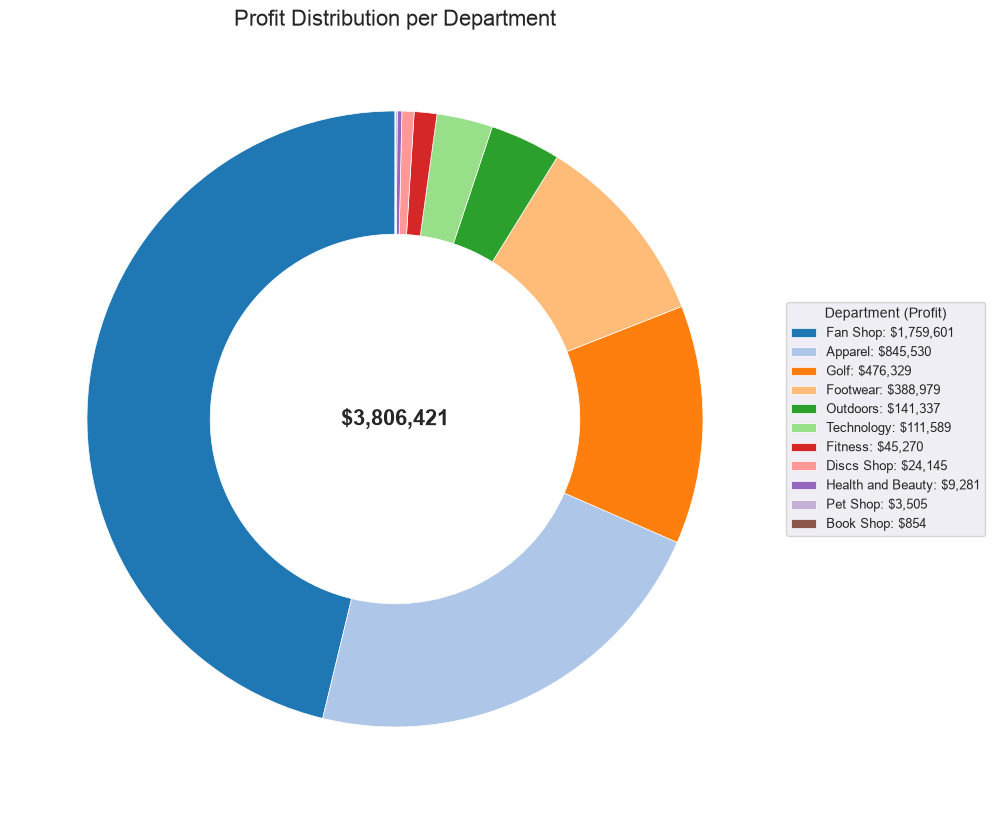

In [10]:
legend_labels = [
    f'{department}: ${profit:,.0f}'
    for department, profit in profit_per_department.items()
]

colors = sns.color_palette("tab20", n_colors=len(profit_per_department))

total_profit = profit_per_department.sum()

plt.figure(figsize=(12, 10))

plt.pie(
    profit_per_department,
    startangle=90,
    colors=colors,
    wedgeprops={'edgecolor': 'white', 'linewidth': .5, 'width': 0.4}
)

plt.text(0, 0, f'${total_profit:,.0f}', ha='center', fontsize=16, va='center', fontweight='bold')

plt.legend(
    legend_labels,
    title='Department (Profit)', 
    loc=6,
    bbox_to_anchor=(1, 0.5))

plt.title('Profit Distribution per Department', fontsize=16)

plt.savefig('../visualizations/profit-distribution-per-department.png', bbox_inches='tight')
plt.show()

### Conclusion

If we look at the numbers for each department in both revenue and profit, we'll see that they strongly agree with each other.

The order of the departments is identical in both revenue and profit, with Fan Shop, Apparel and Golf occupying the top 3 spots.

## Are there departments with high sales but relatively low profitability?

In [11]:
grouped_profit_and_revenue = (
    df.groupby('department_name')
    .agg(
        profit=('order_item_profit', 'sum'),
        revenue=('order_item_total', 'sum')
    )
    .sort_values('profit', ascending=False)
    .reset_index()
)

global_profit = grouped_profit_and_revenue['profit'].sum()
global_revenue = grouped_profit_and_revenue['revenue'].sum()

grouped_profit_and_revenue['profit_share'] = grouped_profit_and_revenue['profit'] / global_profit
grouped_profit_and_revenue['revenue_share'] = grouped_profit_and_revenue['revenue'] / global_revenue

grouped_profit_and_revenue['share_difference'] = grouped_profit_and_revenue['profit_share'] - grouped_profit_and_revenue['revenue_share']

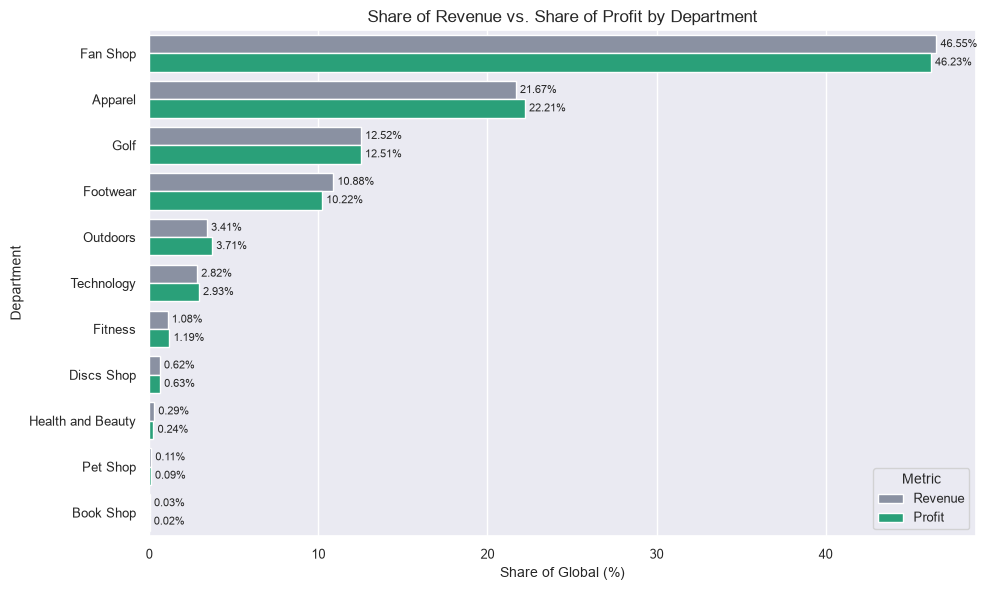

In [12]:
department_shares = pd.DataFrame({
    'Department': grouped_profit_and_revenue['department_name'], 
    'Profit': grouped_profit_and_revenue['profit_share'] * 100, 
    'Revenue': grouped_profit_and_revenue['revenue_share'] * 100
})

department_shares = pd.melt(department_shares, id_vars='Department', var_name='metric', value_name='share')
department_order = grouped_profit_and_revenue['revenue_share'].sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(data=department_shares, x='share', y='Department', hue='metric', hue_order=['Revenue', 'Profit'], palette={'Revenue': '#868FA6', 'Profit': "#16B47F"})

plt.title('Share of Revenue vs. Share of Profit by Department')
plt.xlabel('Share of Global (%)')
plt.ylabel('Department')
plt.legend(title='Metric')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3, fontsize=8)

plt.tight_layout()

plt.savefig('../visualizations/revenue-share-vs-profit-share-by-department.png', bbox_inches='tight')
plt.show()

In [13]:
grouped_profit_and_revenue = grouped_profit_and_revenue.style.format({
    'profit': '€{:,.0f}',
    'revenue': '€{:,.0f}',
    'profit_share': '{:.2%}',
    'revenue_share': '{:.2%}',
    'share_difference': '{:.2%}'
})

grouped_profit_and_revenue

,department_name,profit,revenue,profit_share,revenue_share,share_difference
0,Fan Shop,"€1,759,601","€14,730,174",46.23%,46.55%,-0.32%
1,Apparel,"€845,530","€6,858,959",22.21%,21.67%,0.54%
2,Golf,"€476,329","€3,962,014",12.51%,12.52%,-0.01%
3,Footwear,"€388,979","€3,443,987",10.22%,10.88%,-0.66%
4,Outdoors,"€141,337","€1,078,728",3.71%,3.41%,0.30%
5,Technology,"€111,589","€893,687",2.93%,2.82%,0.11%
6,Fitness,"€45,270","€342,216",1.19%,1.08%,0.11%
7,Discs Shop,"€24,145","€196,911",0.63%,0.62%,0.01%
8,Health and Beauty,"€9,281","€91,250",0.24%,0.29%,-0.04%
9,Pet Shop,"€3,505","€35,835",0.09%,0.11%,-0.02%


### Conclusion

The chart clearly shows that there are no departments with high sales but low profitability. Across all departments, the share of revenue is well aligned with the share of profit.

The highest difference in share of revenue and share of profit is in the Footwear department - 10.22% profit share; 10.88% revenue share; 0.66 percentage points difference.